# EDA ULB Credit Card Fraud - FraudStream Tuần 1

Owner: Phạm Trung Hiếu. Notebook này dùng đúng các hàm trong `scripts/eda_ulb.py` nên số liệu **khớp** với `docs/eda_report.md`.

**Cần:** `data/raw/creditcard.csv` (xem `data/README.md`). Đặt biến môi trường `ULB_CSV` để dùng đường dẫn khác.

In [1]:
import os, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
import eda_ulb as E

DATA = Path(os.environ.get('ULB_CSV', ROOT / 'data/raw/creditcard.csv'))
FIG = ROOT / 'docs/figures'
assert DATA.exists(), f'Không thấy {DATA}; xem data/README.md'
df = E.load_ulb(DATA)
stats = E.compute_stats(df)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Tổng quan, missing, duplicate (Q1, Q2)

In [2]:
print(df.shape)
print('SHA-256:', E.sha256_file(DATA))
display(Markdown(E.comment_quality(stats)))
df.describe().T[['count','mean','std','min','50%','max']].head(8)

(284807, 31)
SHA-256: 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89


Dữ liệu không có missing value. Có **1,081** dòng trùng lặp hoàn toàn (0.380% tổng số; 19 dòng thuộc lớp fraud). ULB không có `transaction_id` nên không thể phân biệt duplicate do lỗi phát lại với hai giao dịch thật giống hệt nhau; trong hệ thống streaming, duplicate được xác định bằng `transaction_id`.

,count,mean,std,min,50%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,84692.000000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,0.018109,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,0.065486,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,0.179846,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.019847,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.054336,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.274187,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,0.040103,120.589494


## 2. Class imbalance (Q1) - Hình 1

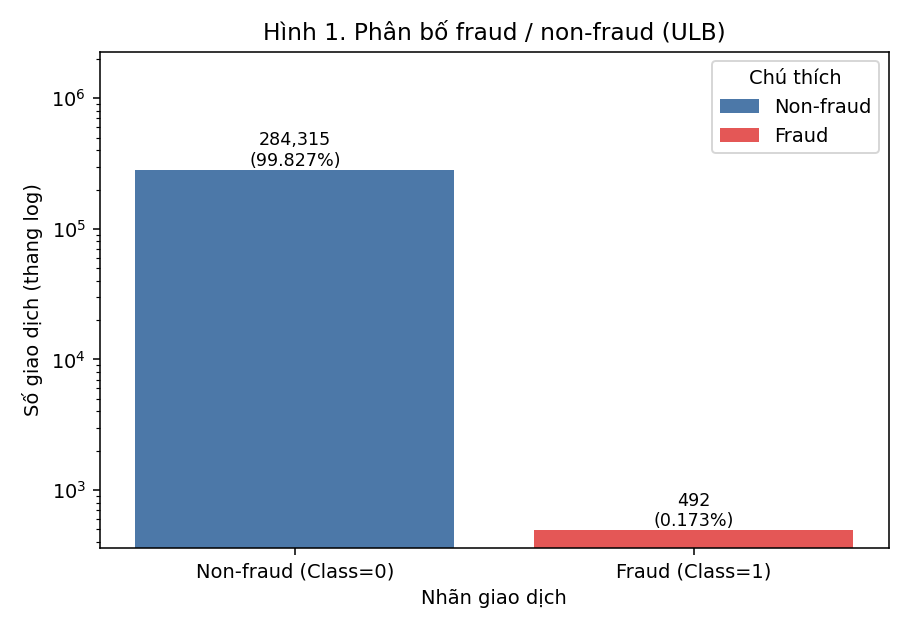

Tập dữ liệu có **284,807** giao dịch, trong đó **492** fraud (**0.173%**); tỷ lệ non-fraud : fraud ≈ **578 : 1**. Một mô hình luôn dự đoán "không fraud" đạt accuracy **99.827%** nhưng Recall = 0 và không phát hiện được giao dịch fraud nào. Vì vậy accuracy không thể là metric duy nhất; dự án dùng Precision, Recall, F1, PR-AUC và False Positive Rate. Baseline của PR-AUC (mô hình ngẫu nhiên) bằng đúng fraud rate = 0.173%.

In [3]:
display(Image(str(E.plot_class_distribution(df, stats, FIG))))
display(Markdown(E.comment_class(stats)))

## 3. Phân bố Amount (Q3) - Hình 2, 5

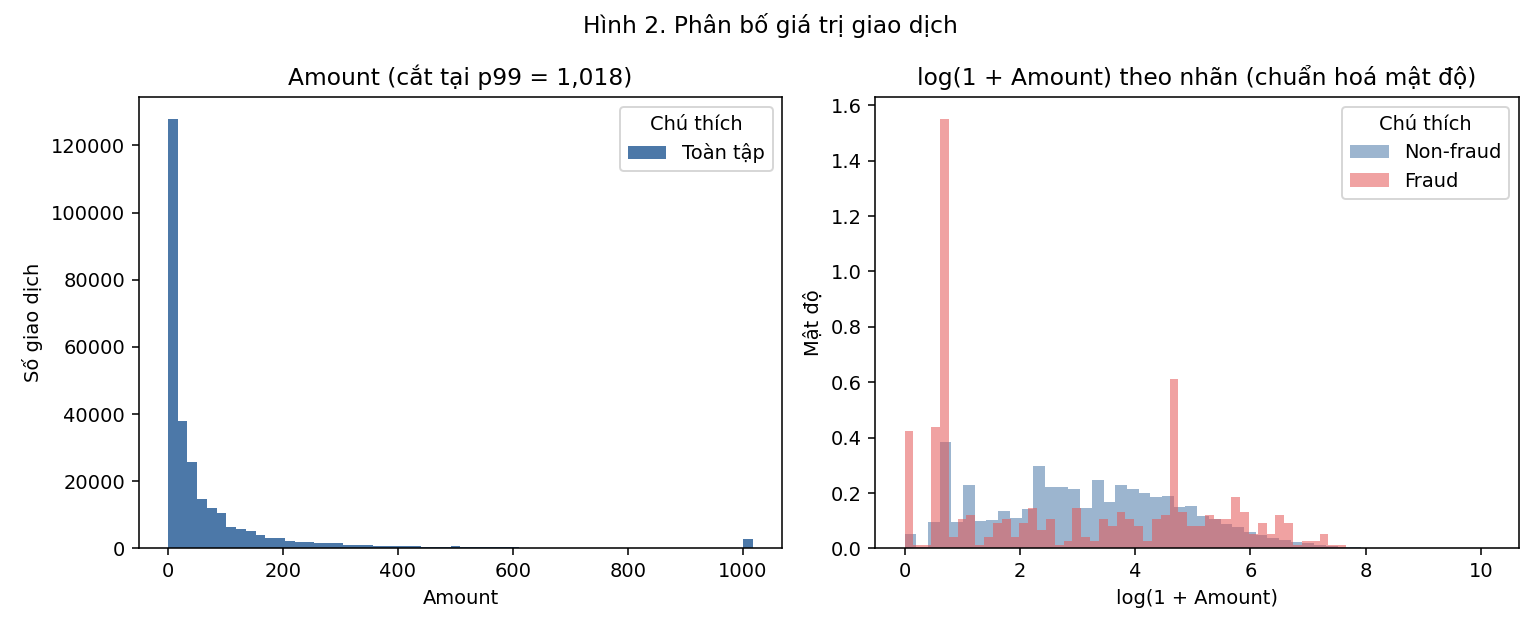

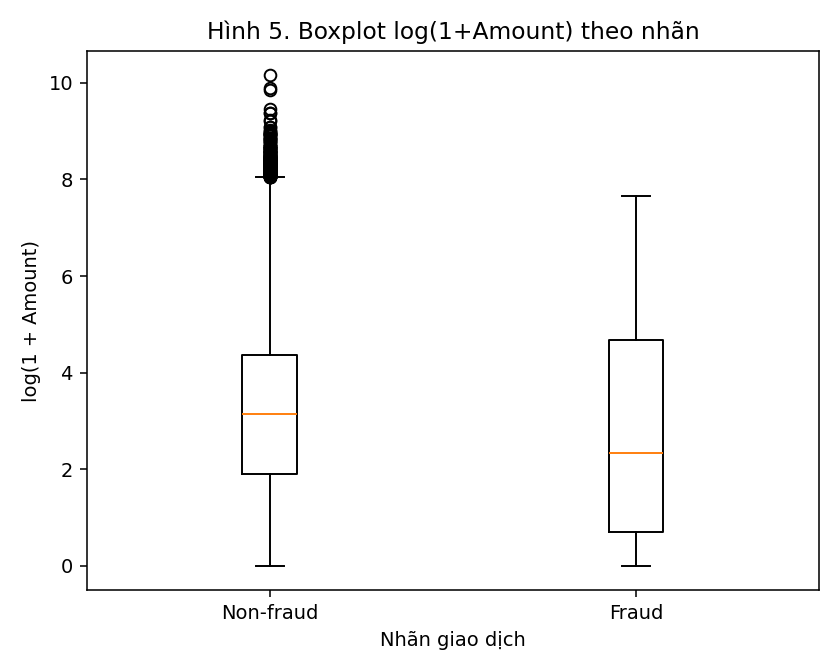

Toàn tập: mean = 88.35, median = 22.00, p95 = 365.00, p99 = 1,017.97, max = 25,691.16, skewness = 16.98 → phân bố lệch phải mạnh (mean > median), cần log-transform hoặc chia bin khi mô hình hoá. Median của fraud = 9.25 so với 22.00 của non-fraud (fraud thấp hơn); mean fraud = 122.21 vs 88.29; max fraud = 2,125.87. Có **1,825** giao dịch Amount = 0 (trong đó 27 fraud) → cần quy tắc data-quality riêng cho amount bằng 0.

,all,legit,fraud
count,284807.000000,284315.000000,492.000000
mean,88.349619,88.291022,122.211321
std,250.120109,250.105092,256.683288
min,0.000000,0.000000,0.000000
p25,5.600000,5.650000,1.000000
median,22.000000,22.000000,9.250000
p75,77.165000,77.050000,105.890000
p95,365.000000,364.409000,640.905000
p99,1017.970000,1016.966400,1357.427900
max,25691.160000,25691.160000,2125.870000


In [4]:
display(Image(str(E.plot_amount_distribution(df, stats, FIG))))
display(Image(str(E.plot_amount_boxplot(df, stats, FIG))))
display(Markdown(E.comment_amount(stats)))
pd.DataFrame({'all': stats['amount_all'], 'legit': stats['amount_legit'], 'fraud': stats['amount_fraud']})

## 4. Fraud rate theo nhóm Amount (Q4) - Hình 3

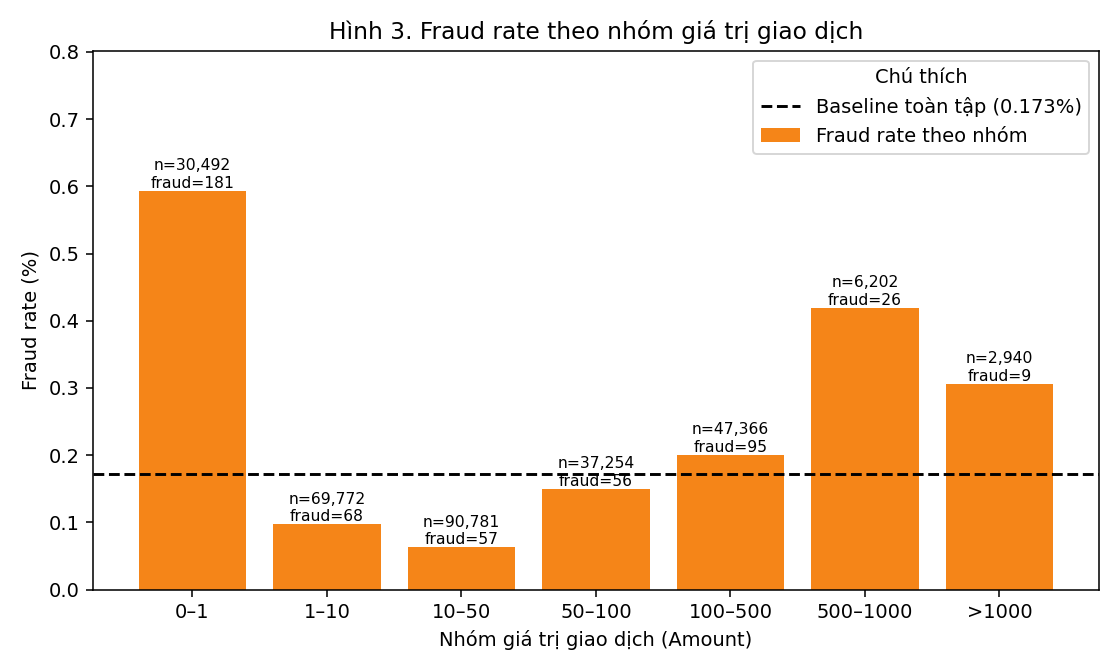

,key,n,n_fraud,rate
0,0–1,30492,181,0.005936
1,1–10,69772,68,0.000975
2,10–50,90781,57,0.000628
3,50–100,37254,56,0.001503
4,100–500,47366,95,0.002006
5,500–1000,6202,26,0.004192
6,>1000,2940,9,0.003061


Nhóm có fraud rate cao nhất (đủ mẫu) là **0–1**: 0.594% (181/30,492), gấp 3.4 lần baseline 0.173%. Nhóm thấp nhất là **10–50**: 0.063% (57/90,781), bằng 0.4 lần baseline. Nhóm có ít fraud (<3) bị loại khỏi so sánh vì nhiễu. Ý nghĩa nghiệp vụ: amount có mang thông tin nhưng không đủ riêng lẻ → nên so sánh amount với lịch sử của chính thẻ (`amount_vs_avg_7d`) thay vì chỉ dùng ngưỡng tuyệt đối.

In [5]:
display(Image(str(E.plot_fraud_rate_by_amount(df, stats, FIG))))
display(pd.DataFrame(stats['amount_bins']))
display(Markdown(E.comment_amount_bins(stats)))

## 5. Fraud rate theo thời gian (Q4) - Hình 4

`Time` là giây kể từ giao dịch đầu tiên nên đây là giờ **tương đối**.

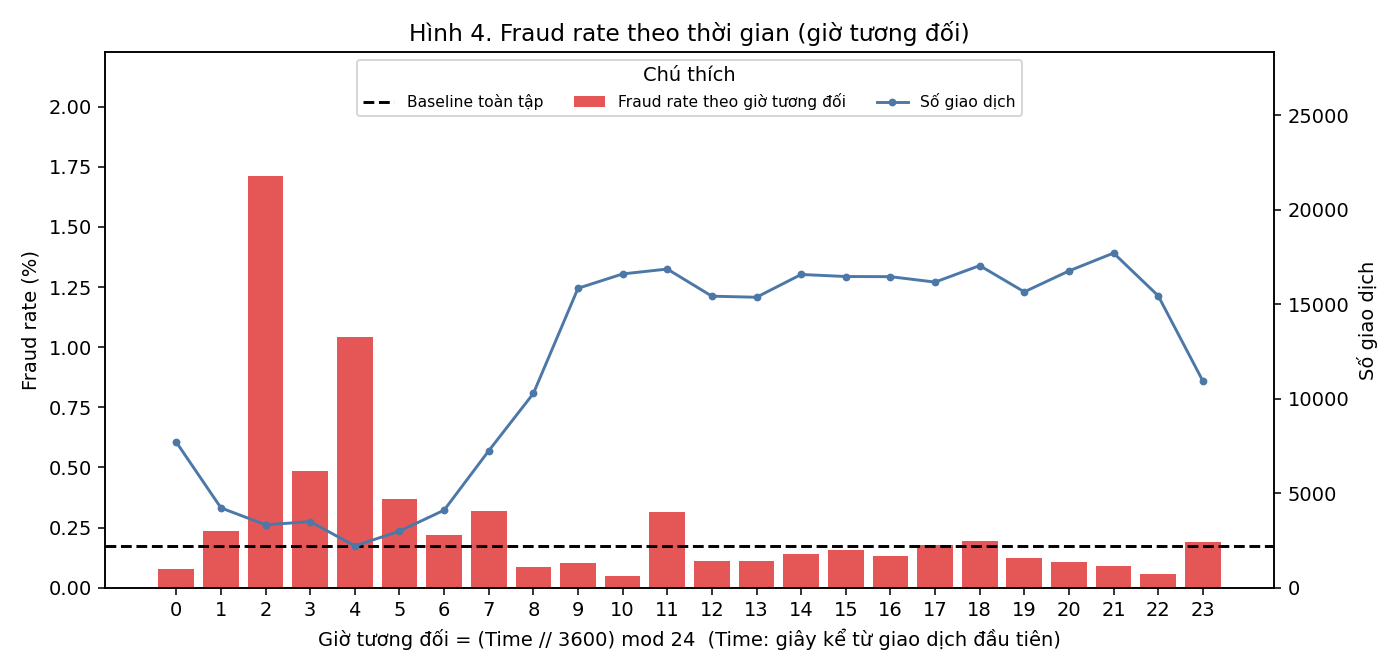

,key,n,n_fraud,rate
0,0,7695,6,0.000780
1,1,4220,10,0.002370
2,2,3328,57,0.017127
3,3,3492,17,0.004868
4,4,2209,23,0.010412
5,5,2990,11,0.003679
6,6,4101,9,0.002195
7,7,7243,23,0.003175
8,8,10276,9,0.000876
9,9,15838,16,0.001010


3 giờ tương đối có fraud rate cao nhất (≥3 fraud): giờ 2: 1.713% (57/3,328); giờ 4: 1.041% (23/2,209); giờ 3: 0.487% (17/3,492); baseline 0.173%. Lưu ý: `Time` là số giây kể từ giao dịch đầu tiên nên đây là giờ **tương đối**, chưa phải giờ đồng hồ; dữ liệu chỉ trải 48.0 giờ nên mỗi giờ chỉ lặp 1–2 lần → kết luận mang tính gợi ý. Trong hệ thống thật nên dùng `hour_of_day` theo múi giờ của chủ thẻ.

In [6]:
display(Image(str(E.plot_fraud_rate_by_time(df, stats, FIG))))
display(pd.DataFrame(stats['hour_table']))
display(Markdown(E.comment_hour(stats)))

## 6. Tương quan (chỉ train) và chia tập theo thời gian (Q7) - Hình 6

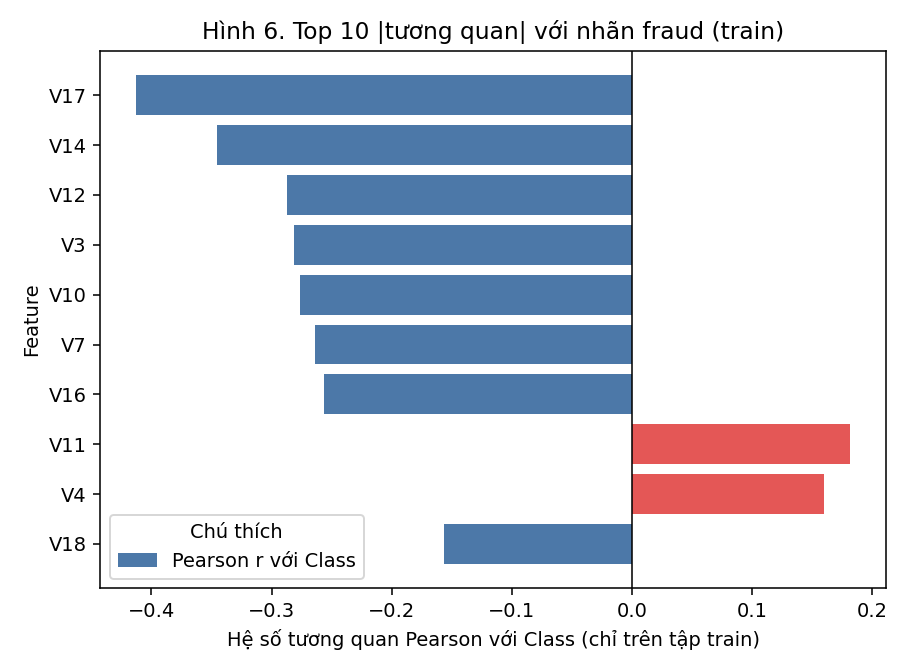

Top 5 theo |r| trên tập train: V17 (-0.41), V14 (-0.35), V12 (-0.29), V3 (-0.28), V10 (-0.28). Các cột V1–V28 là thành phần PCA ẩn danh nên không diễn giải được theo nghiệp vụ; chỉ dùng để dựng **baseline model** trên ULB, không đưa vào feature v1 của hệ thống streaming. Tương quan được tính riêng trên train để không rò rỉ thông tin từ validation/test.

,n,n_fraud,rate,time_start,time_end
train,170884.0,360.0,0.002107,0.0,120396.0
validation,56961.0,57.0,0.001001,120396.0,145247.0
test,56962.0,75.0,0.001317,145248.0,172792.0


Chia theo thứ tự `Time` (60/20/20), không xáo trộn: train: 170,884 dòng, 360 fraud (0.211%); validation: 56,961 dòng, 57 fraud (0.100%); test: 56,962 dòng, 75 fraud (0.132%). 

In [7]:
display(Image(str(E.plot_top_corr(df, stats, FIG))))
display(Markdown(E.comment_corr(stats)))
display(pd.DataFrame(stats['splits']).T)
display(Markdown(E.comment_splits(stats)))

## 7. Kiểm tra nhanh leakage khi chia tập

Tập sau không được có `Time` nhỏ hơn tập trước.

In [8]:
sp = stats['splits']
assert sp['train']['time_end'] <= sp['validation']['time_start'] <= sp['validation']['time_end'] <= sp['test']['time_start']
print('OK: chia theo thời gian, không chồng lấn')

OK: chia theo thời gian, không chồng lấn


## 8. Xuất báo cáo

Để sinh `docs/eda_report.md` + `docs/eda_stats.json` đầy đủ (kèm IEEE-CIS nếu có):

```bash
python scripts/eda_ulb.py --data data/raw/creditcard.csv [--ieee-transaction data/raw/ieee/train_transaction.csv]
```